# 2.5 Event detection

Four tweet-supported emotion peaks. **31** evidence tweets. E03 has **exactly 5** evidence tweets; the keyword tweet is contextual and was **not** used in the timeline z-score.

No causation is claimed. This notebook does not rerun event detection.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

def find_root() -> Path:
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "outputs").is_dir() and (p / "src").is_dir():
            return p
    raise FileNotFoundError(
        "Cannot find the project root (need outputs/ and src/). "
        "Open this notebook from the repo, from notebooks/, or from a guideline folder."
    )

ROOT = find_root()
OUT = ROOT / "outputs"
print("ROOT =", ROOT)
print("This notebook reads shipped CSVs and PNGs only.")
print("It does not open IFB.db, does not open any analysis database,")
print("and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.")


ROOT = C:\Users\yosef\OneDrive\שולחן העבודה\IFB-project
This notebook reads shipped CSVs and PNGs only.
It does not open IFB.db, does not open any analysis database,
and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.


events 4 evidence tweets 31
event_id
E01     6
E02    10
E03     5
E04    10
dtype: int64
E03 evidence 5
[embedded figure] emotion_over_time_monthly.png (246,430 bytes)
DONE event verification


,event_id,date,window_start,window_end,period,resolution,emotion,source,share,share_weighted,baseline_share,z_score,n_raw,n_emotion,n_posts_window,n_positive,n_neutral,n_negative,pct_positive,pct_neutral,pct_negative,theme,theme_hits,theme_fraction,why_selected,external
0,E01,2022-03-01,2022-03-01,2022-04-01,2022-03,monthly,fear,keyword_tweets,0.005108,NaN,0.001457,4.5856,3720,19,3720,912,2613,195,24.52,70.24,5.24,Official flood warnings (eastern Australia / NSW),18,0.9474,"monthly keyword_tweets fear share=0.51% (baseline 0.15%, z=4.5856) with 19 fear posts out of 3720 in 2022-03. Local peak vs neighbouring bins. Tweet theme: Official flood warnings (eastern Australia / NSW) (18 matching emotion tweets, 94.7% of that emotion in the window). This describes an observed change in the sample, not a proven cause.",Bureau of Meteorology NSW accounts posted flood warnings in Feb–Mar 2022; those texts are in the keyword corpus because they contain the word 'follow' (follow SES advice).
1,E02,2022-11-21,2022-11-21,2022-11-28,2022-11-21,weekly,joy,keyword_tweets,0.102178,NaN,0.054618,4.9515,597,61,597,152,412,33,25.46,69.01,5.53,Thanksgiving greetings in user timelines,23,0.3770,"weekly keyword_tweets joy share=10.22% (baseline 5.46%, z=4.9515) with 61 joy posts out of 597 in 2022-11-21. Local peak vs neighbouring bins. Tweet theme: Thanksgiving greetings in user timelines (23 matching emotion tweets, 37.7% of that emotion in the window). This describes an observed change in the sample, not a proven cause.",US Thanksgiving 2022 fell on 24 November. Keyword IFB posts that week include 'Happy Thanksgiving'. That does not prove Thanksgiving caused the joy share.
2,E03,2022-02-21,2022-02-21,2022-02-28,2022-02-21,weekly,fear,timeline,0.004222,0.004222,0.002349,3.4695,3553,15,3553,640,2410,503,18.01,67.83,14.16,Posts mentioning the 2022 Russia–Ukraine war,4,0.2667,"weekly timeline fear share=0.42% (baseline 0.23%, z=3.4695) with 15 fear posts out of 3553 in 2022-02-21. Local peak vs neighbouring bins. Tweet theme: Posts mentioning the 2022 Russia–Ukraine war (4 matching emotion tweets, 26.7% of that emotion in the window). This describes an observed change in the sample, not a proven cause.",A subset of fear-labeled timeline tweets in the 21–27 Feb 2022 week mention Ukraine or explosions there. Other fear tweets in the same week do not. This is not treated as proof that the invasion caused the IFB sample's fear share.
3,E04,2021-11-22,2021-11-22,2021-11-29,2021-11-22,weekly,joy,timeline,0.106506,0.106509,0.079783,5.2194,2075,221,2075,410,1428,237,19.76,68.82,11.42,Thanksgiving greetings in user timelines,24,0.1086,"weekly timeline joy share=10.65% (baseline 7.98%, z=5.2194) with 221 joy posts out of 2075 in 2021-11-22. Local peak vs neighbouring bins. Tweet theme: Thanksgiving greetings in user timelines (24 matching emotion tweets, 10.9% of that emotion in the window). This describes an observed change in the sample, not a proven cause.",US Thanksgiving 2021 fell on 25 November. Timeline joy tweets that week include 'Happy Thanksgiving'. That does not prove Thanksgiving caused the joy share.


,event_id,source,original_text,engagement_note
16,E03,timeline,RT @ajplus: Thousands of people are fleeing Ukraine following Russia's invasion.\n\nHuman rights groups are warning of a possible humanitaria…,not stored on nlp_posts
17,E03,timeline,"RT @oioiisogolden: !! UKRAINE\ni woke up at 5am today because of the sounds of explosions. and let me tell you, it was one of the scariest m…",not stored on nlp_posts
18,E03,timeline,Russia is in Ukraine for interest whole western countries in panic. https://t.co/9yRSmfZlTB,not stored on nlp_posts
29,E03,timeline,"RT @oioiisogolden: !! UKRAINE\ni woke up at 5am today because of the sounds of explosions. and let me tell you, it was one of the scariest m…",not stored on nlp_posts
30,E03,keyword_tweets,US has warned Ukraine of new intelligence suggesting Russia is about to attack https://t.co/CPf0nue00L #followforfollow,"not stored on nlp_posts; keyword census, same calendar week as E03"


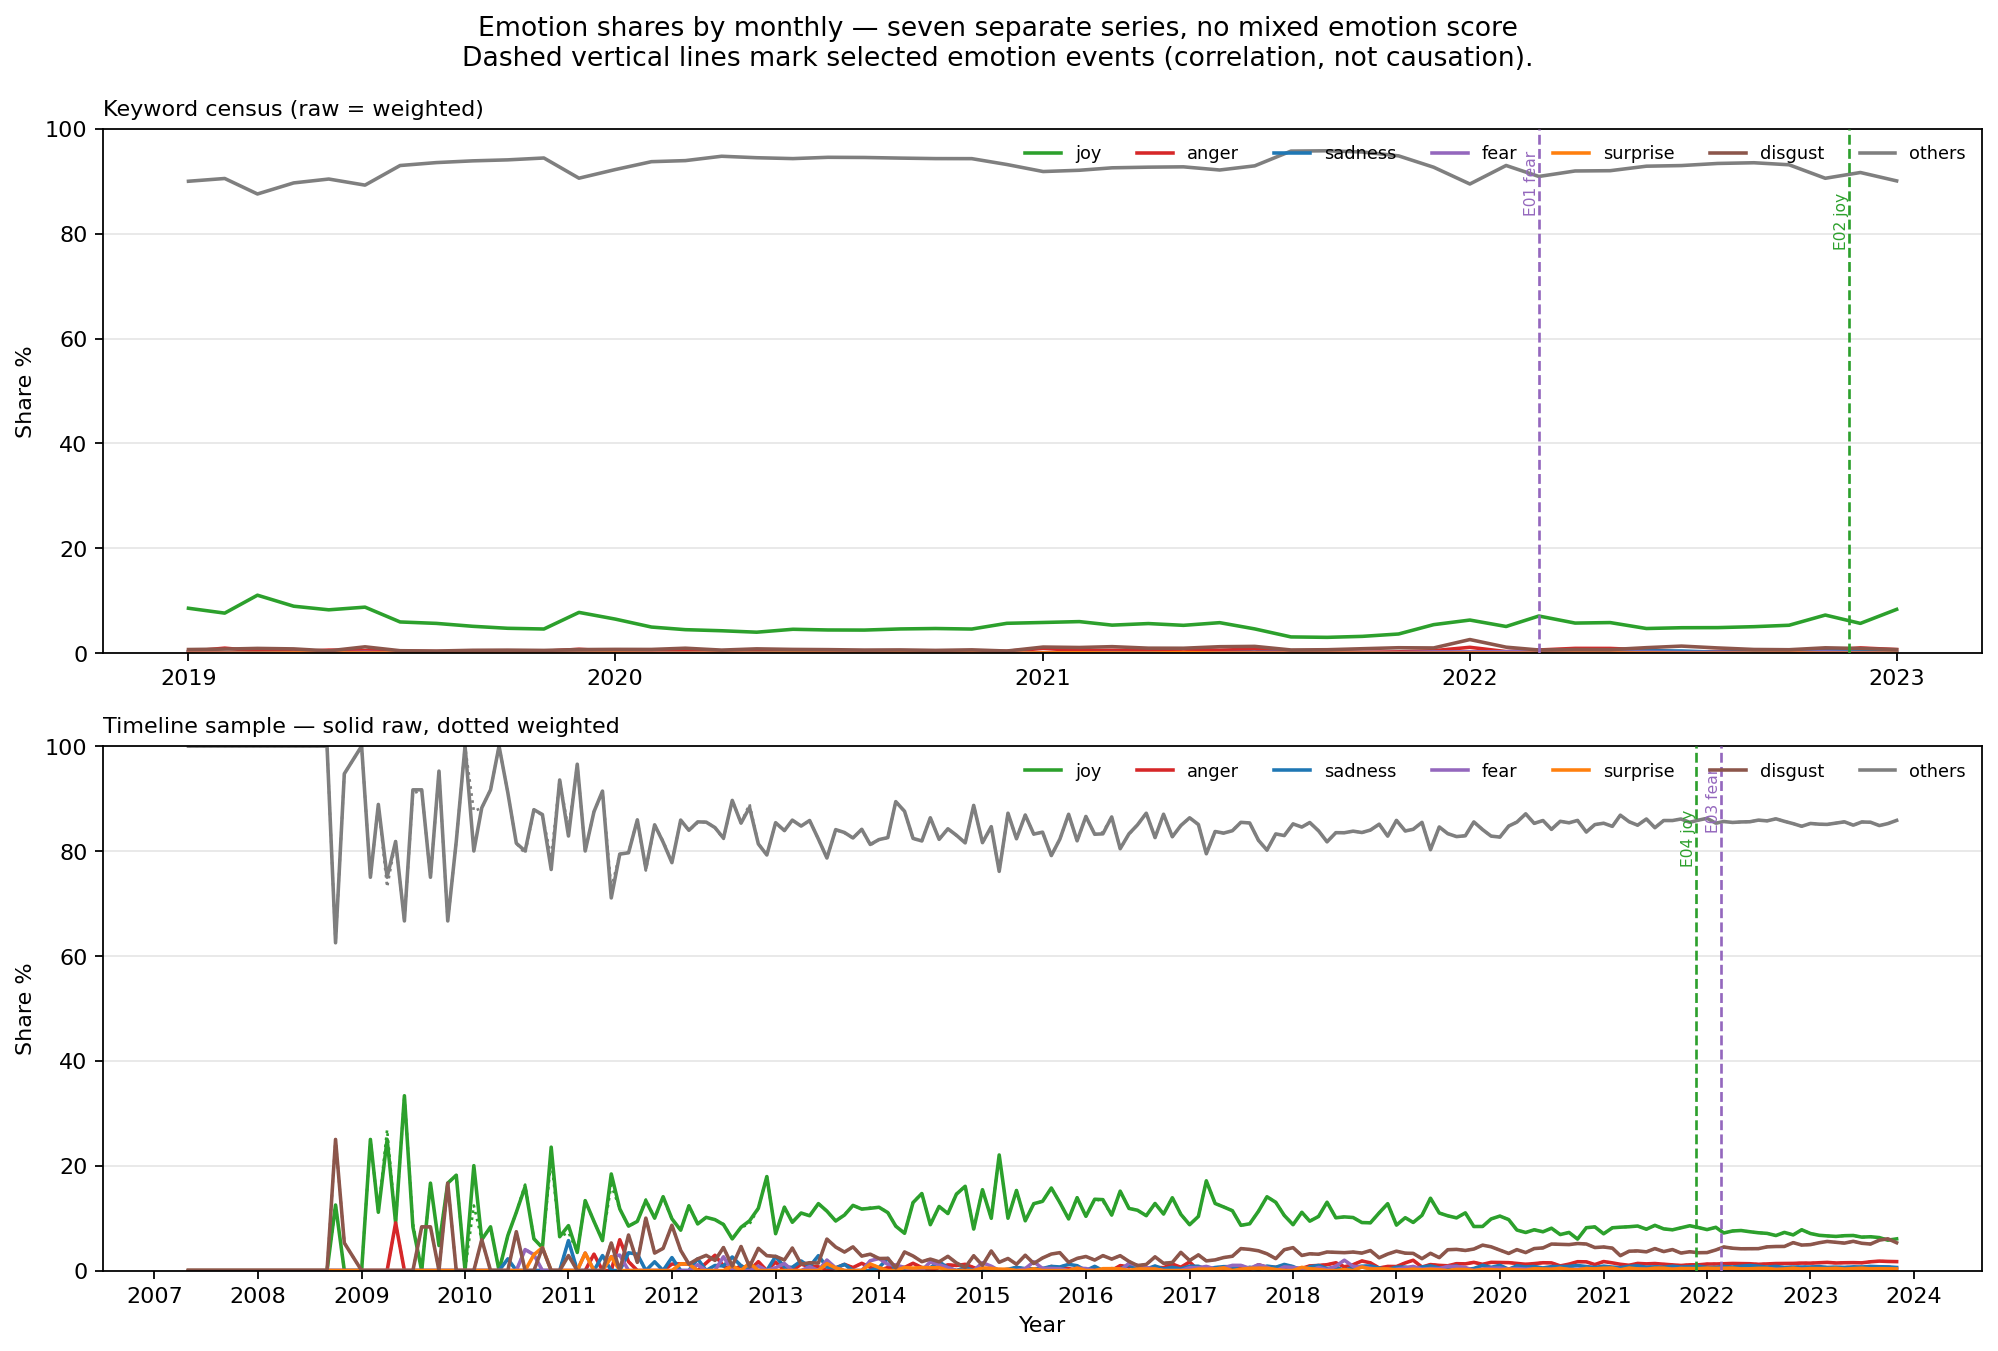

In [2]:
events = pd.read_csv(OUT / "detected_events.csv", encoding="utf-8-sig")
evid = pd.read_csv(OUT / "event_tweet_evidence.csv", encoding="utf-8-sig")
print("events", len(events), "evidence tweets", len(evid))
assert len(events) == 4
assert len(evid) == 31
display(events)
print(evid.groupby("event_id").size())
e03 = evid[evid["event_id"].astype(str).str.upper() == "E03"]
print("E03 evidence", len(e03))
display(e03[["event_id", "source"] + [c for c in e03.columns if "note" in c.lower() or c == "original_text"][:3]])
display(Image(filename=str(OUT / "event_plots" / "emotion_over_time_monthly.png")))
print("DONE event verification")
